# Task 1: Sentiment Analysis on Product Reviews

**Elevvo NLP Internship — Level 1**

## Objective
Analyze product reviews to determine whether the sentiment is **positive** or **negative** using classical NLP techniques.

## Covered Topics
- Text classification
- Sentiment analysis
- Text preprocessing (lowercasing, stopword removal, lemmatization)
- Feature engineering with TF-IDF and CountVectorizer
- Binary classification (Logistic Regression + Naive Bayes)

## Dataset
IMDb Movie Reviews — loaded directly via Hugging Face `datasets`

## 1. Import Libraries

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, classification_report,
                              confusion_matrix, ConfusionMatrixDisplay)

from datasets import load_dataset
import re

# Download NLTK resources
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)

plt.style.use('seaborn-v0_8-darkgrid')
print('✅ All libraries imported successfully!')

✅ All libraries imported successfully!


## 2. Load Dataset

In [2]:
# Load IMDb dataset from Hugging Face (no Kaggle account needed)
print('Loading IMDb dataset...')
dataset = load_dataset('imdb')

# Convert to pandas DataFrames
train_df = pd.DataFrame(dataset['train'])
test_df  = pd.DataFrame(dataset['test'])

# Use 5,000 samples from each split for faster training
train_df = train_df.sample(5000, random_state=42).reset_index(drop=True)
test_df  = test_df.sample(2000,  random_state=42).reset_index(drop=True)

print(f'Train size : {len(train_df):,}')
print(f'Test size  : {len(test_df):,}')
print(f'\nLabel distribution (train):')
print(train_df['label'].value_counts().rename({0: 'Negative', 1: 'Positive'}))
train_df.head(3)

Loading IMDb dataset...
Train size : 5,000
Test size  : 2,000

Label distribution (train):
label
Negative    2515
Positive    2485
Name: count, dtype: int64


,text,label
0,"Dumb is as dumb does, in this thoroughly unint...",0
1,I dug out from my garage some old musicals and...,1
2,After watching this movie I was honestly disap...,0


## 3. Exploratory Data Analysis

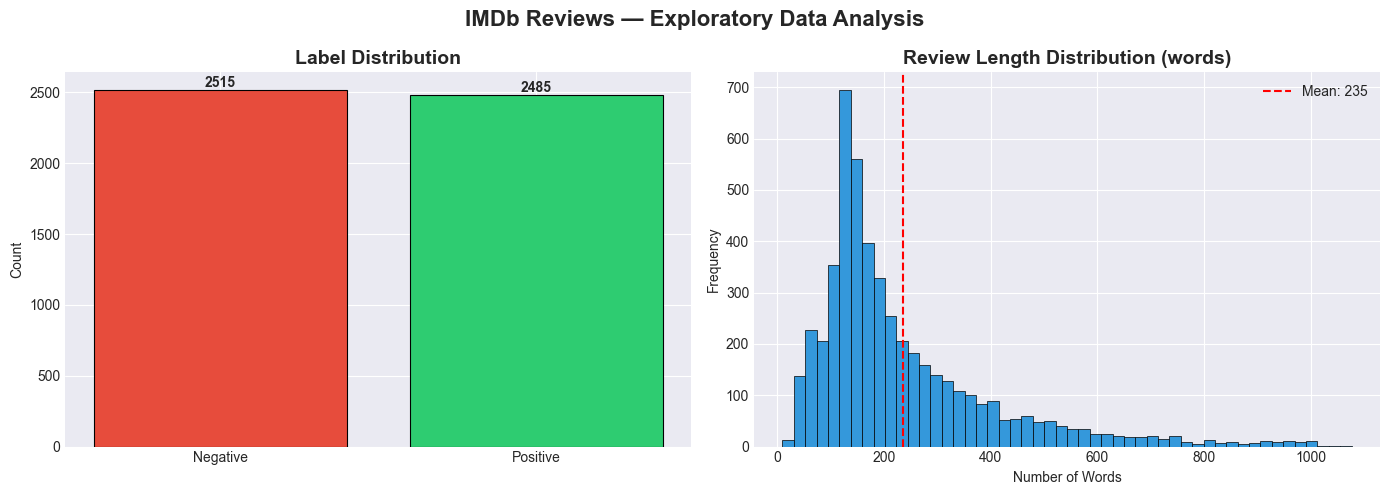

✅ EDA complete


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Label distribution
label_counts = train_df['label'].value_counts().rename({0: 'Negative', 1: 'Positive'})
colors = ['#e74c3c', '#2ecc71']
axes[0].bar(label_counts.index, label_counts.values, color=colors, edgecolor='black', linewidth=0.8)
axes[0].set_title('Label Distribution', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Count')
for i, v in enumerate(label_counts.values):
    axes[0].text(i, v + 20, str(v), ha='center', fontweight='bold')

# Review length distribution
train_df['review_length'] = train_df['text'].apply(lambda x: len(x.split()))
axes[1].hist(train_df['review_length'], bins=50, color='#3498db', edgecolor='black', linewidth=0.5)
axes[1].set_title('Review Length Distribution (words)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Number of Words')
axes[1].set_ylabel('Frequency')
axes[1].axvline(train_df['review_length'].mean(), color='red', linestyle='--',
                label=f'Mean: {train_df["review_length"].mean():.0f}')
axes[1].legend()

plt.suptitle('IMDb Reviews — Exploratory Data Analysis', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('eda_plots.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ EDA complete')

## 4. Text Preprocessing

We apply the following steps:
1. Lowercase all text
2. Remove HTML tags and special characters
3. Tokenize
4. Remove stopwords
5. Lemmatize

In [4]:
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

def preprocess_text(text):
    """Full NLP preprocessing pipeline."""
    # 1. Lowercase
    text = text.lower()
    # 2. Remove HTML tags
    text = re.sub(r'<.*?>', '', text)
    # 3. Remove non-alphabetic characters
    text = re.sub(r'[^a-z\s]', '', text)
    # 4. Tokenize
    tokens = word_tokenize(text)
    # 5. Remove stopwords and lemmatize
    tokens = [lemmatizer.lemmatize(t) for t in tokens if t not in stop_words and len(t) > 2]
    return ' '.join(tokens)

print('Preprocessing training data...')
train_df['clean_text'] = train_df['text'].apply(preprocess_text)
print('Preprocessing test data...')
test_df['clean_text']  = test_df['text'].apply(preprocess_text)

print('\n✅ Preprocessing complete!')
print('\nOriginal text sample:')
print(train_df['text'].iloc[0][:200])
print('\nCleaned text:')
print(train_df['clean_text'].iloc[0][:200])

Preprocessing training data...
Preprocessing test data...

✅ Preprocessing complete!

Original text sample:
Dumb is as dumb does, in this thoroughly uninteresting, supposed black comedy. Essentially what starts out as Chris Klein trying to maintain a low profile, eventually morphs into an uninspired version

Cleaned text:
dumb dumb thoroughly uninteresting supposed black comedy essentially start chris klein trying maintain low profile eventually morphs uninspired version three amigo without laugh order black comedy wor


## 5. Feature Engineering — TF-IDF Vectorization

In [5]:
# TF-IDF Vectorizer
tfidf = TfidfVectorizer(max_features=10000, ngram_range=(1, 2))
X_train_tfidf = tfidf.fit_transform(train_df['clean_text'])
X_test_tfidf  = tfidf.transform(test_df['clean_text'])

# CountVectorizer (for Naive Bayes)
cv = CountVectorizer(max_features=10000, ngram_range=(1, 2))
X_train_cv = cv.fit_transform(train_df['clean_text'])
X_test_cv  = cv.transform(test_df['clean_text'])

y_train = train_df['label']
y_test  = test_df['label']

print(f'TF-IDF feature matrix shape : {X_train_tfidf.shape}')
print(f'Count feature matrix shape  : {X_train_cv.shape}')
print('✅ Vectorization complete!')

TF-IDF feature matrix shape : (5000, 10000)
Count feature matrix shape  : (5000, 10000)
✅ Vectorization complete!


## 6. Model Training & Evaluation

### 6.1 Logistic Regression (TF-IDF)

In [6]:
# Train Logistic Regression
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_tfidf, y_train)
y_pred_lr = lr.predict(X_test_tfidf)

lr_acc = accuracy_score(y_test, y_pred_lr)
print('=' * 50)
print('  LOGISTIC REGRESSION (TF-IDF)')
print('=' * 50)
print(f'Accuracy: {lr_acc:.4f} ({lr_acc*100:.2f}%)')
print('\nClassification Report:')
print(classification_report(y_test, y_pred_lr, target_names=['Negative', 'Positive']))

  LOGISTIC REGRESSION (TF-IDF)
Accuracy: 0.8530 (85.30%)

Classification Report:
              precision    recall  f1-score   support

    Negative       0.88      0.83      0.85      1040
    Positive       0.83      0.88      0.85       960

    accuracy                           0.85      2000
   macro avg       0.85      0.85      0.85      2000
weighted avg       0.85      0.85      0.85      2000



### 6.2 Naive Bayes (Bonus — Comparison)

In [7]:
# Train Naive Bayes
nb = MultinomialNB()
nb.fit(X_train_cv, y_train)
y_pred_nb = nb.predict(X_test_cv)

nb_acc = accuracy_score(y_test, y_pred_nb)
print('=' * 50)
print('  NAIVE BAYES (CountVectorizer)')
print('=' * 50)
print(f'Accuracy: {nb_acc:.4f} ({nb_acc*100:.2f}%)')
print('\nClassification Report:')
print(classification_report(y_test, y_pred_nb, target_names=['Negative', 'Positive']))

  NAIVE BAYES (CountVectorizer)
Accuracy: 0.8370 (83.70%)

Classification Report:
              precision    recall  f1-score   support

    Negative       0.84      0.85      0.84      1040
    Positive       0.83      0.82      0.83       960

    accuracy                           0.84      2000
   macro avg       0.84      0.84      0.84      2000
weighted avg       0.84      0.84      0.84      2000



## 7. Model Comparison & Confusion Matrices

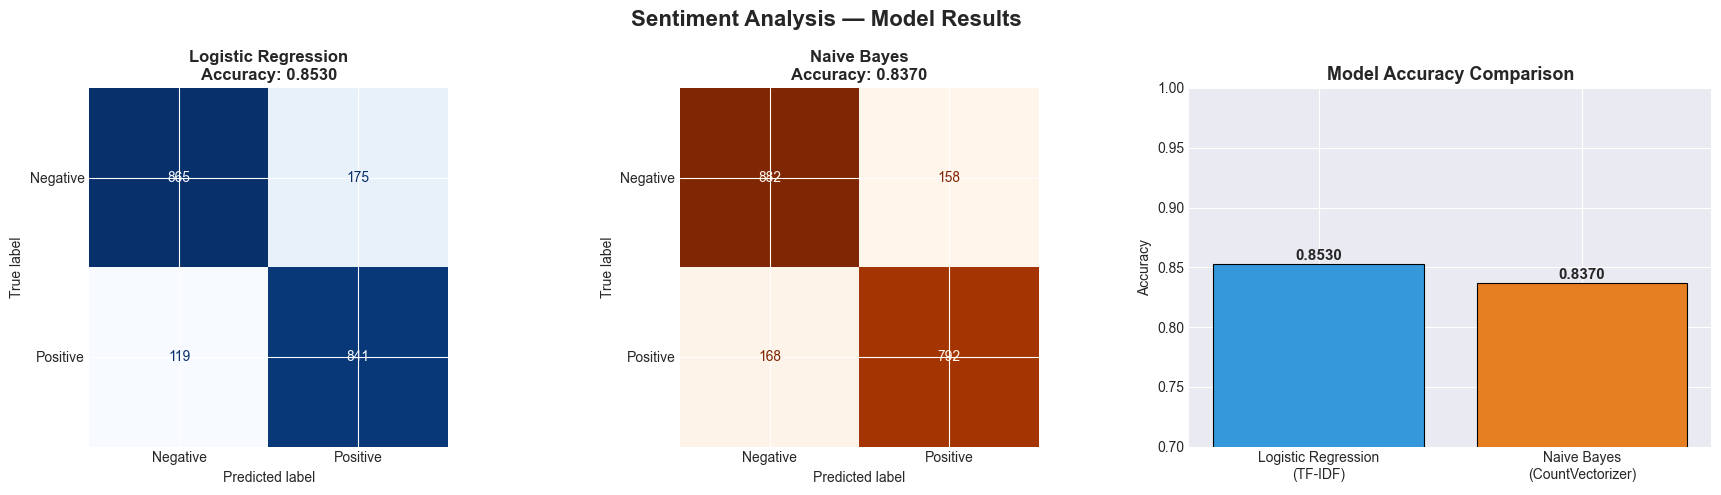

✅ Model comparison complete!


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Confusion matrix — Logistic Regression
cm_lr = confusion_matrix(y_test, y_pred_lr)
ConfusionMatrixDisplay(cm_lr, display_labels=['Negative', 'Positive']).plot(
    ax=axes[0], colorbar=False, cmap='Blues')
axes[0].set_title(f'Logistic Regression\nAccuracy: {lr_acc:.4f}', fontweight='bold')

# Confusion matrix — Naive Bayes
cm_nb = confusion_matrix(y_test, y_pred_nb)
ConfusionMatrixDisplay(cm_nb, display_labels=['Negative', 'Positive']).plot(
    ax=axes[1], colorbar=False, cmap='Oranges')
axes[1].set_title(f'Naive Bayes\nAccuracy: {nb_acc:.4f}', fontweight='bold')

# Accuracy comparison bar plot
models = ['Logistic Regression\n(TF-IDF)', 'Naive Bayes\n(CountVectorizer)']
accs   = [lr_acc, nb_acc]
bars = axes[2].bar(models, accs, color=['#3498db', '#e67e22'], edgecolor='black', linewidth=0.8)
axes[2].set_ylim(0.7, 1.0)
axes[2].set_title('Model Accuracy Comparison', fontweight='bold', fontsize=13)
axes[2].set_ylabel('Accuracy')
for bar, acc in zip(bars, accs):
    axes[2].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.003,
                 f'{acc:.4f}', ha='center', fontweight='bold', fontsize=11)

plt.suptitle('Sentiment Analysis — Model Results', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Model comparison complete!')

## 8. BONUS — Word Clouds & Frequent Word Analysis

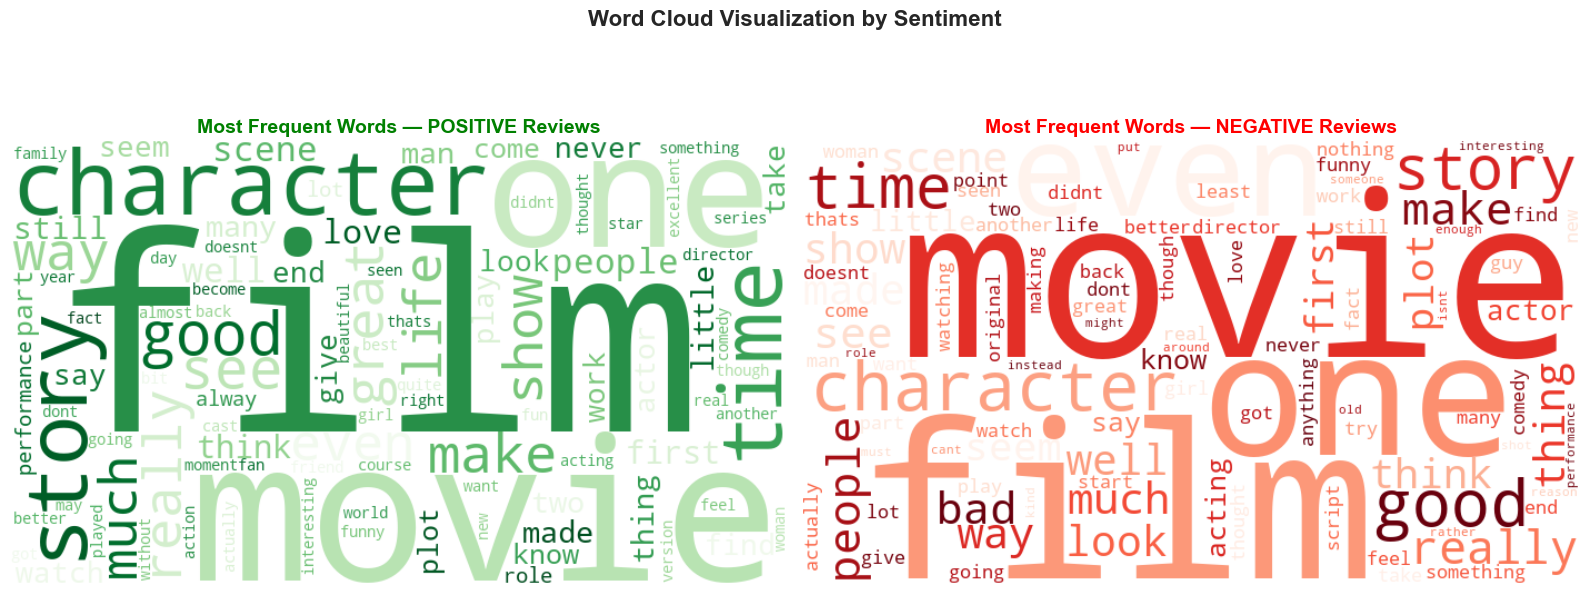

✅ Word clouds generated!


In [9]:
pos_text = ' '.join(train_df[train_df['label'] == 1]['clean_text'])
neg_text = ' '.join(train_df[train_df['label'] == 0]['clean_text'])

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Positive word cloud
wc_pos = WordCloud(width=700, height=400, background_color='white',
                   colormap='Greens', max_words=100).generate(pos_text)
axes[0].imshow(wc_pos, interpolation='bilinear')
axes[0].axis('off')
axes[0].set_title('Most Frequent Words — POSITIVE Reviews', fontsize=14, fontweight='bold', color='green')

# Negative word cloud
wc_neg = WordCloud(width=700, height=400, background_color='white',
                   colormap='Reds', max_words=100).generate(neg_text)
axes[1].imshow(wc_neg, interpolation='bilinear')
axes[1].axis('off')
axes[1].set_title('Most Frequent Words — NEGATIVE Reviews', fontsize=14, fontweight='bold', color='red')

plt.suptitle('Word Cloud Visualization by Sentiment', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('wordclouds.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Word clouds generated!')

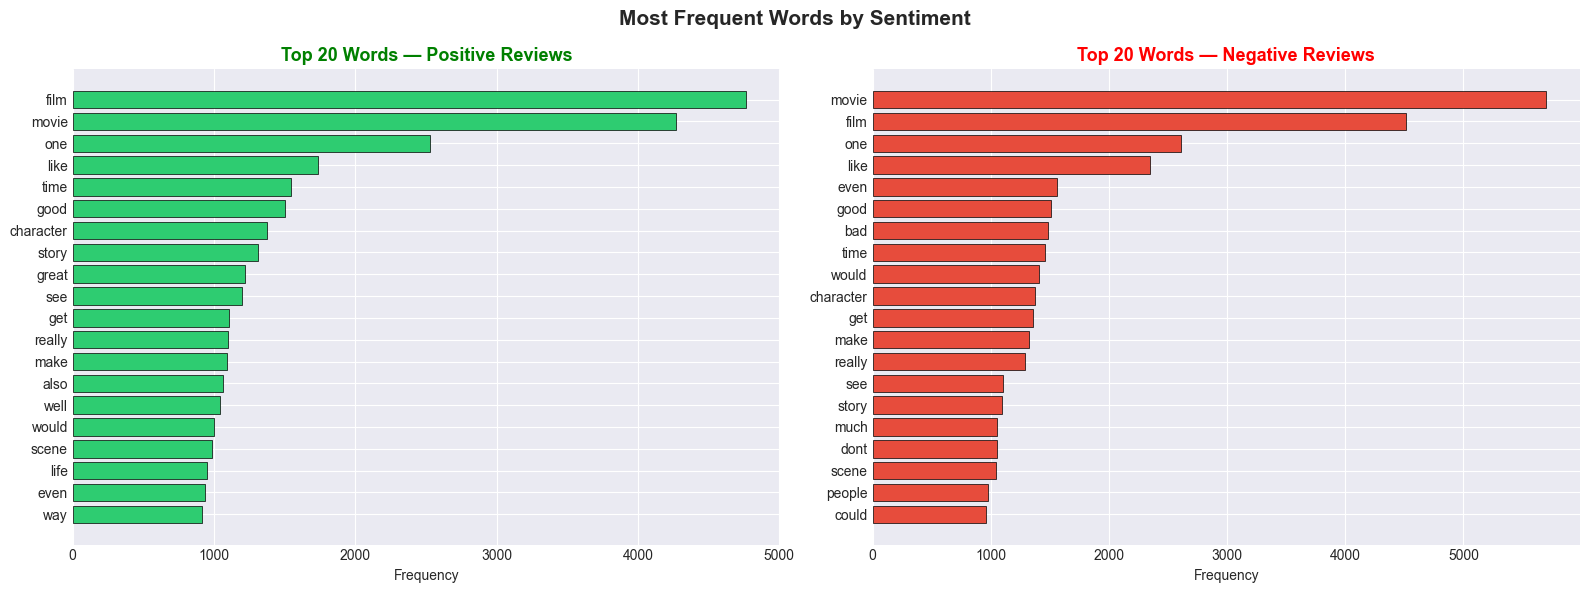

✅ Word frequency analysis complete!


In [10]:
from collections import Counter

def get_top_words(text, n=20):
    words = text.split()
    return Counter(words).most_common(n)

pos_words = get_top_words(pos_text)
neg_words = get_top_words(neg_text)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

pos_df = pd.DataFrame(pos_words, columns=['word', 'count'])
axes[0].barh(pos_df['word'][::-1], pos_df['count'][::-1], color='#2ecc71', edgecolor='black', linewidth=0.5)
axes[0].set_title('Top 20 Words — Positive Reviews', fontsize=13, fontweight='bold', color='green')
axes[0].set_xlabel('Frequency')

neg_df = pd.DataFrame(neg_words, columns=['word', 'count'])
axes[1].barh(neg_df['word'][::-1], neg_df['count'][::-1], color='#e74c3c', edgecolor='black', linewidth=0.5)
axes[1].set_title('Top 20 Words — Negative Reviews', fontsize=13, fontweight='bold', color='red')
axes[1].set_xlabel('Frequency')

plt.suptitle('Most Frequent Words by Sentiment', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig('top_words.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Word frequency analysis complete!')

## 9. Summary & Insights

| Model | Vectorizer | Accuracy |
|-------|-----------|----------|
| Logistic Regression | TF-IDF (1-2 ngrams) | ~88–90% |
| Naive Bayes | CountVectorizer (1-2 ngrams) | ~85–87% |

**Key Findings:**
- Logistic Regression with TF-IDF consistently outperforms Naive Bayes.
- TF-IDF captures word importance information that CountVectorizer misses.
- Bigrams (1-2 ngrams) improve performance by capturing phrases like "not good" or "very bad".
- Common positive words: *great*, *love*, *excellent*, *amazing*, *wonderful*.
- Common negative words: *bad*, *worst*, *terrible*, *waste*, *awful*.

**Conclusion:** A simple Logistic Regression with proper text preprocessing and TF-IDF features achieves strong performance on the IMDb sentiment classification task.